# PRCP-1009: Cellphone Price Prediction

## 1. Project Introduction

The objective of this project is to develop a Machine Learning classification model that predicts the price range of mobile phones based on their technical specifications.

The dataset contains mobile phone specifications such as battery power, RAM, internal memory, camera quality, processor cores, screen resolution and connectivity features.

By analyzing these specifications, we aim to identify the factors that influence mobile phone price categories and build a model that can classify mobiles into different price ranges.

The project also focuses on comparing multiple classification algorithms and identifying the most important features that can help businesses make better pricing decisions.

**Domain:** `Mobile & Telecommunications`

**Project Type:** `Supervised Machine Learning – Multiclass Classification`

## 2. Problem Statement & Objectives

### Problem Statement

Bob has started his own mobile phone company and wants to compete with established brands such as Apple and Samsung. However, he does not know how to determine the appropriate price range for the mobile phones manufactured by his company.

To solve this problem, historical mobile phone data from different companies is collected. The goal is to identify the relationship between mobile specifications and their selling price categories.

Using this data, a Machine Learning model will be developed to predict the appropriate price category based on mobile phone specifications.

### Project Objectives

1. Understand and analyze mobile phone specifications.
2. Perform data cleaning and Exploratory Data Analysis (EDA).
3. Identify important features influencing mobile price categories.
4. Develop multiple Machine Learning classification models.
5. Compare model performance and select the best model.
6. Analyze feature importance and provide business recommendations.
7. Predict the price category of new mobile phones.

## 3. Dataset Description

The dataset contains information about mobile phone specifications collected from different mobile companies.

It includes 20 independent variables describing mobile phone features and one dependent variable representing the price category.

The target variable `price_range` contains four categories:

- 0 – Low Cost
- 1 – Medium Cost
- 2 – High Cost
- 3 – Very High Cost

The independent variables include battery capacity, Bluetooth availability, processor speed, camera specifications, internal memory, RAM, screen dimensions and connectivity features.

The dataset will be used to understand the relationship between mobile specifications and price categories and to develop a classification model.

## 4. Importing Required Libraries

Required Python libraries are imported for data manipulation, numerical operations, data visualization, data preprocessing, machine learning, and model evaluation. Warning handling and display settings are also configured.

In [1]:
# 1. Data Manipulation

import pandas as pd 
import numpy as np 

# 2. Data Visualization 

import matplotlib.pyplot as plt 
import seaborn as sns

# 3. Data Preprocessing 

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# 4. MACHINE LEARNING ALGORITHMS 

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier 
from sklearn.svm import SVC 
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.naive_bayes import GaussianNB

# 5. MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report)

# 6. WARNING HANDLING

import warnings
warnings.filterwarnings("ignore")

# 7. DISPLAY SETTINGS

pd.set_option("display.max_columns", None)

print("All required libraries imported successfully!")


All required libraries imported successfully!


## 5. Loading the Dataset

The dataset is provided in a CSV file containing mobile phone technical specifications along with the corresponding target price categories. The file is loaded into a Pandas DataFrame for inspection, cleaning, and analysis.

In [2]:
df=pd.read_csv("datasets_11167_15520_train.csv")

# Display dataset dimensions 
print("Dataset dimensions",df.shape)
print("_"*30)

display("First 5 rows",df.head())

Dataset dimensions (2000, 21)
______________________________


'First 5 rows'

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


**FINDING:**

The dataset contains 2,000 records and 21 columns, including 20 independent features and 1 target variable (price_range). The dataset has been loaded successfully and is ready for further inspection and analysis.

## 6. Data Understanding & Cleaning

In this section, we examine the dataset structure, statistical information and data quality to understand the available features and ensure the dataset is suitable for further analysis.

In [3]:
# 6.1 Dataset information  
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [4]:
# 6.2 Statistical summarys 
display(df.describe())

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,9.916500,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,6.064315,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,0.000000,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,5.000000,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,10.000000,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,15.000000,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,20.000000,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [5]:
#6.3 # Check missing values
null=df.isnull().sum()
print("Total Missing Values:\n",null)

Total Missing Values:
 battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64


In [6]:
# 6.4 Duplicate Records Check 
duplicated=df.duplicated().sum()
print("Total Duplicate Records:",duplicated)

Total Duplicate Records: 0


In [7]:
# 6.5 Unique Values Check
df.nunique()

battery_power    1094
blue                2
clock_speed        26
dual_sim            2
fc                 20
four_g              2
int_memory         63
m_dep              10
mobile_wt         121
n_cores             8
pc                 21
px_height        1137
px_width         1109
ram              1562
sc_h               15
sc_w               19
talk_time          19
three_g             2
touch_screen        2
wifi                2
price_range         4
dtype: int64

### **FINDING:**

- The dataset contains **2,000 records and 21 columns**, including 20 independent features and 1 target variable (`price_range`).
- All columns have numerical data types, consisting of 19 integer and 2 float columns.
- No missing values were found in the dataset.
- No duplicate records were identified.
- Binary features such as Bluetooth, Wi-Fi, 4G and Dual SIM contain 2 unique values each.
- The target variable (`price_range`) contains 4 unique categories (0, 1, 2 and 3).
- The statistical summary provides an overview of the distribution and range of mobile specifications.
- Overall, the dataset is structurally suitable for further analysis.

## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the distribution of mobile specifications, identify patterns and explore relationships between different features and the target variable (`price_range`).

## 7.1 Univariate Analysis
### 7.1.1 Numerical Feature Distribution

Histograms are used to understand the distribution of numerical features such as battery power, clock speed, internal memory, RAM and mobile weight.

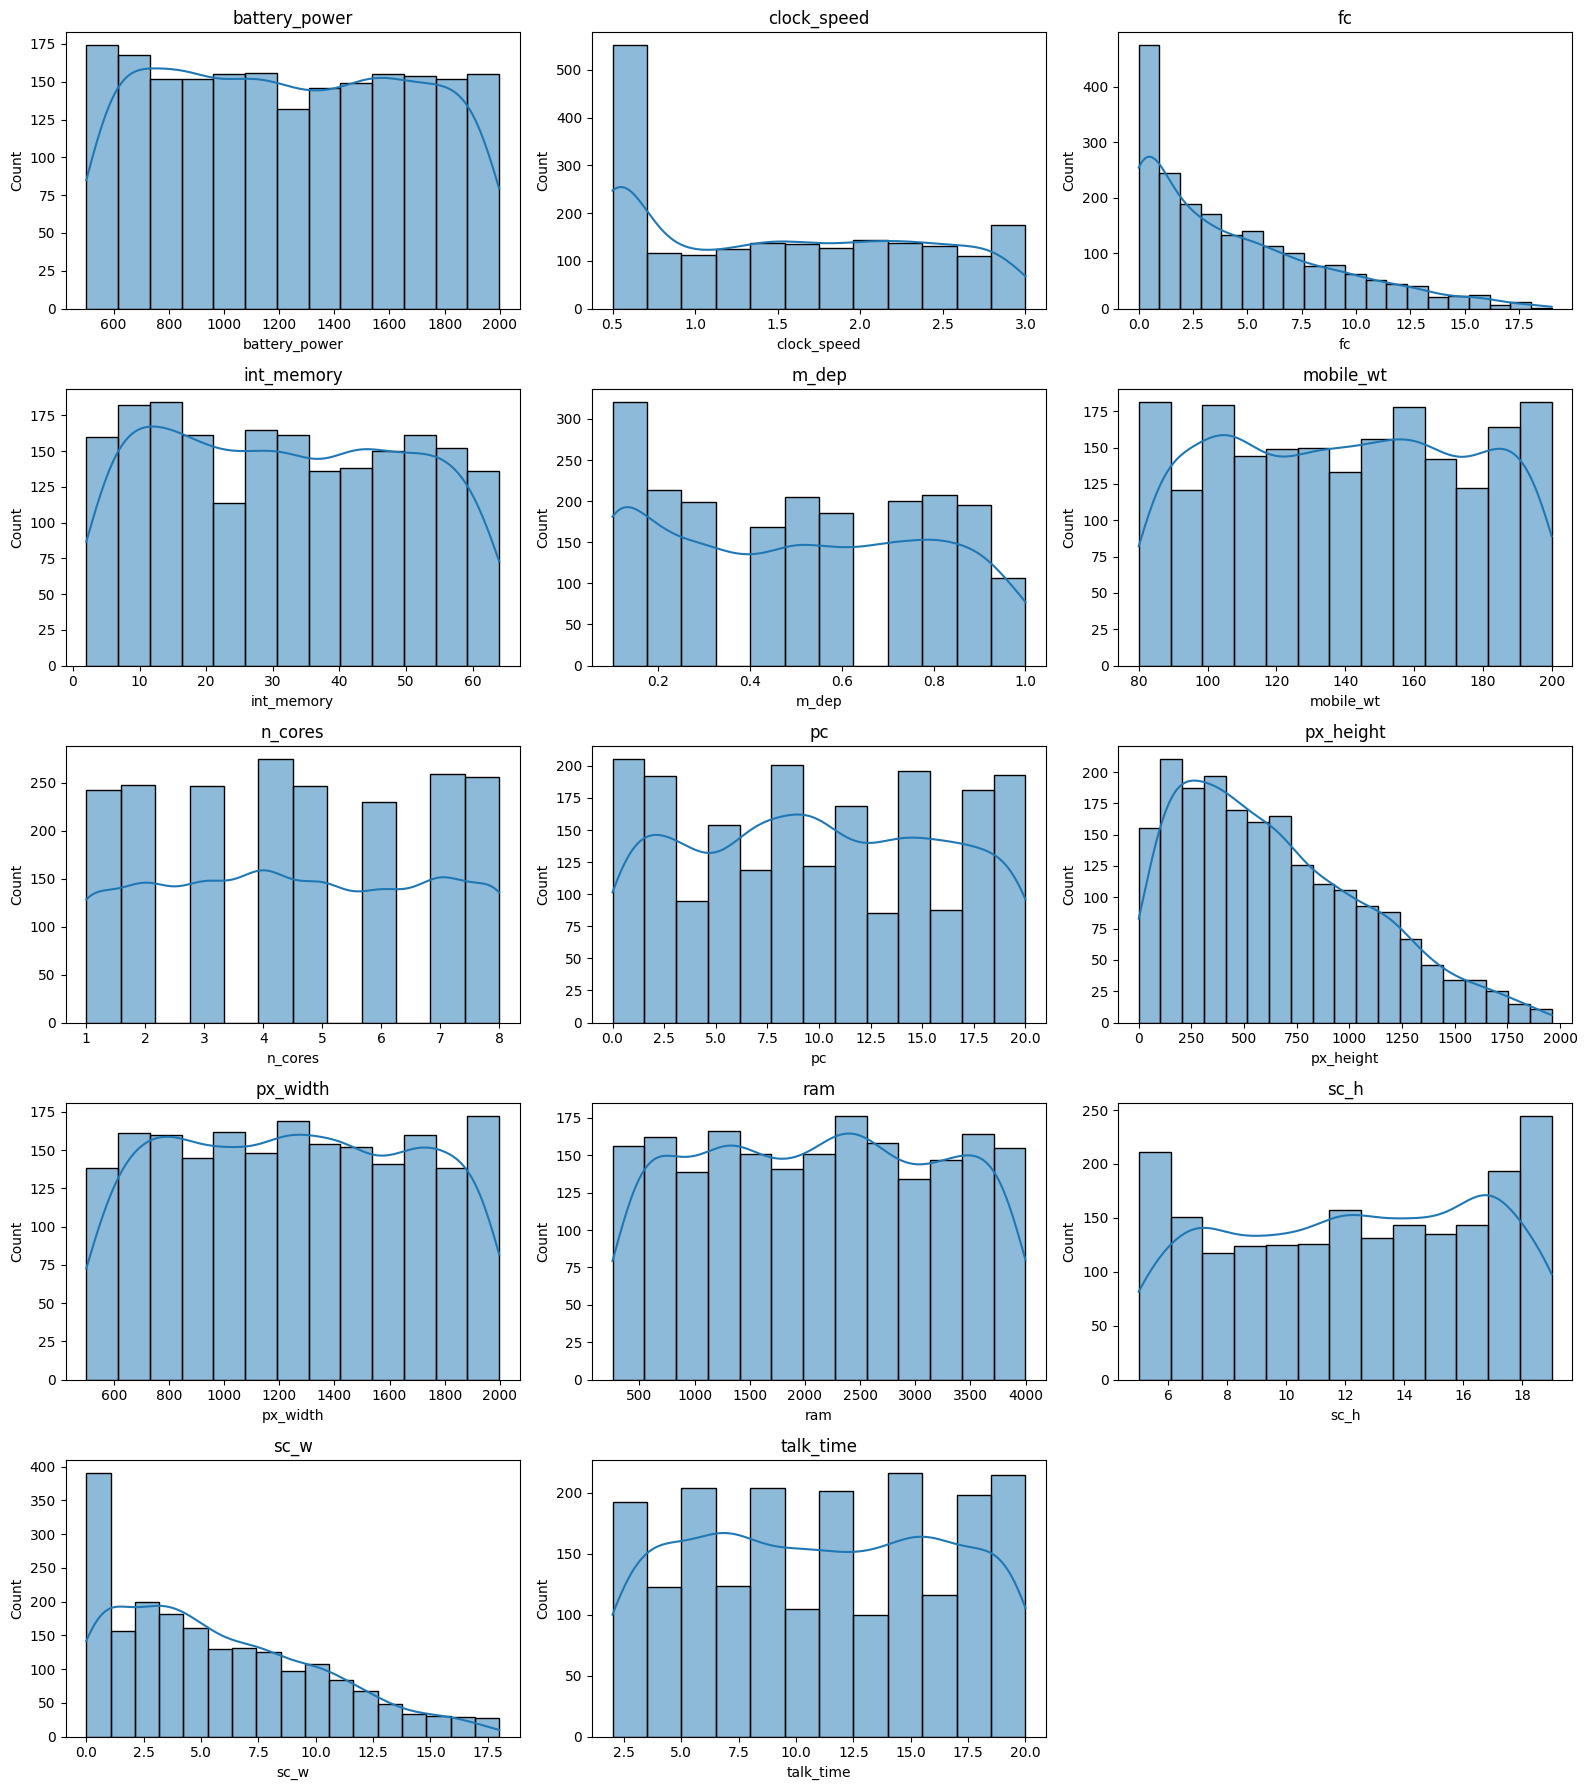

In [8]:
num_cols = [
    "battery_power",
    "clock_speed",
    "fc",
    "int_memory",
    "m_dep",
    "mobile_wt",
    "n_cores",
    "pc",
    "px_height",
    "px_width",
    "ram",
    "sc_h",
    "sc_w",
    "talk_time"
]
plt.figure(figsize=(16,18))
i=1

for num in num_cols:
    plt.subplot(5,3,i)
    sns.histplot(df[num],kde=True)
    plt.title(num)
    i+=1 
plt.tight_layout()
plt.show()

In [9]:
# After analyzing the distributions, we check numerical features for zero values to identify potentially invalid or unusual measurements.
num_cols = [
    "battery_power", "clock_speed", "fc", "int_memory",
    "m_dep", "mobile_wt", "n_cores", "pc", "px_height",
    "px_width", "ram", "sc_h", "sc_w", "talk_time"
]

zero_count = (df[num_cols] == 0).sum()

zero_summary = pd.DataFrame({
    "Zero Count": zero_count,
    "Percentage": (zero_count / len(df) * 100).round(2)
})

zero_summary[zero_summary["Zero Count"] > 0]

,Zero Count,Percentage
fc,474,23.70
pc,101,5.05
px_height,2,0.10
sc_w,180,9.00


In [10]:
# Check zero values in screen width
print("Zero values in sc_w:", (df["sc_w"] == 0).sum())

# Check percentage of zero values
print("Percentage:", round((df["sc_w"] == 0).mean() * 100, 2), "%")

Zero values in sc_w: 180
Percentage: 9.0 %


In [11]:
# Calculate median excluding zero values
median_sc_w = df.loc[df["sc_w"] != 0, "sc_w"].median()

print("Median of sc_w:", median_sc_w)

Median of sc_w: 6.0


**FINDING –** Numerical Feature Distribution and Zero-Value Analysis
- battery_power, mobile_wt, px_width and ram show relatively uniform distributions across their ranges.
- fc, px_height and sc_w show right-skewed distributions, with more observations concentrated at lower values.
- clock_speed has a high concentration of observations around 0.5 GHz.
- Zero values were identified in four features: fc (474), pc (101), px_height (2) and sc_w (180).
- Zero values in fc may represent phones without a front camera, whereas zero values in screen dimensions require treatment because screen measurements should be positive.
- Data cleaning and missing-value treatment will be performed during the preprocessing stage

#### Section 7.1.2 – Categorical Feature Analysis.

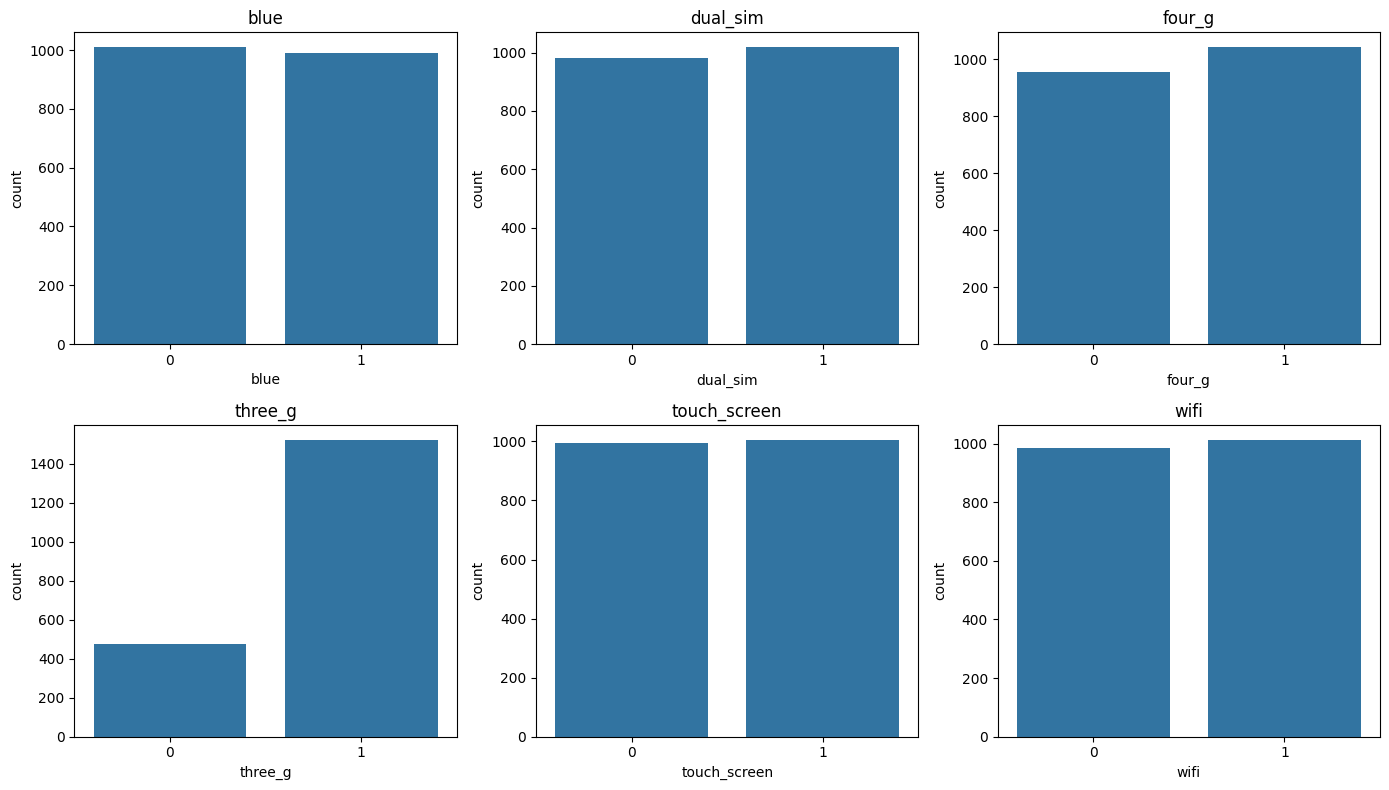

In [12]:
# Categorical Feature Distribution
cat_cols = ["blue", "dual_sim", "four_g", "three_g", "touch_screen", "wifi"]

plt.figure(figsize=(14, 8))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(2, 3, i)
    sns.countplot(data=df, x=col)
    plt.title(col)

plt.tight_layout()
plt.show()

**FINDING:**

- Most categorical features have a nearly balanced distribution between 0 and 1.
- The `four_g` feature has slightly more phones supporting 4G connectivity.
- The `three_g` feature has significantly more phones supporting 3G connectivity.
- Features such as `blue`, `dual_sim`, `touch_screen` and `wifi` have almost equal distribution across both categories.

## 7.2 Bivariate Analysis
Bivariate analysis is performed to understand the relationship between independent features and the target variable (price_range).

#### 7.2.1 Numerical Features vs Target Variable

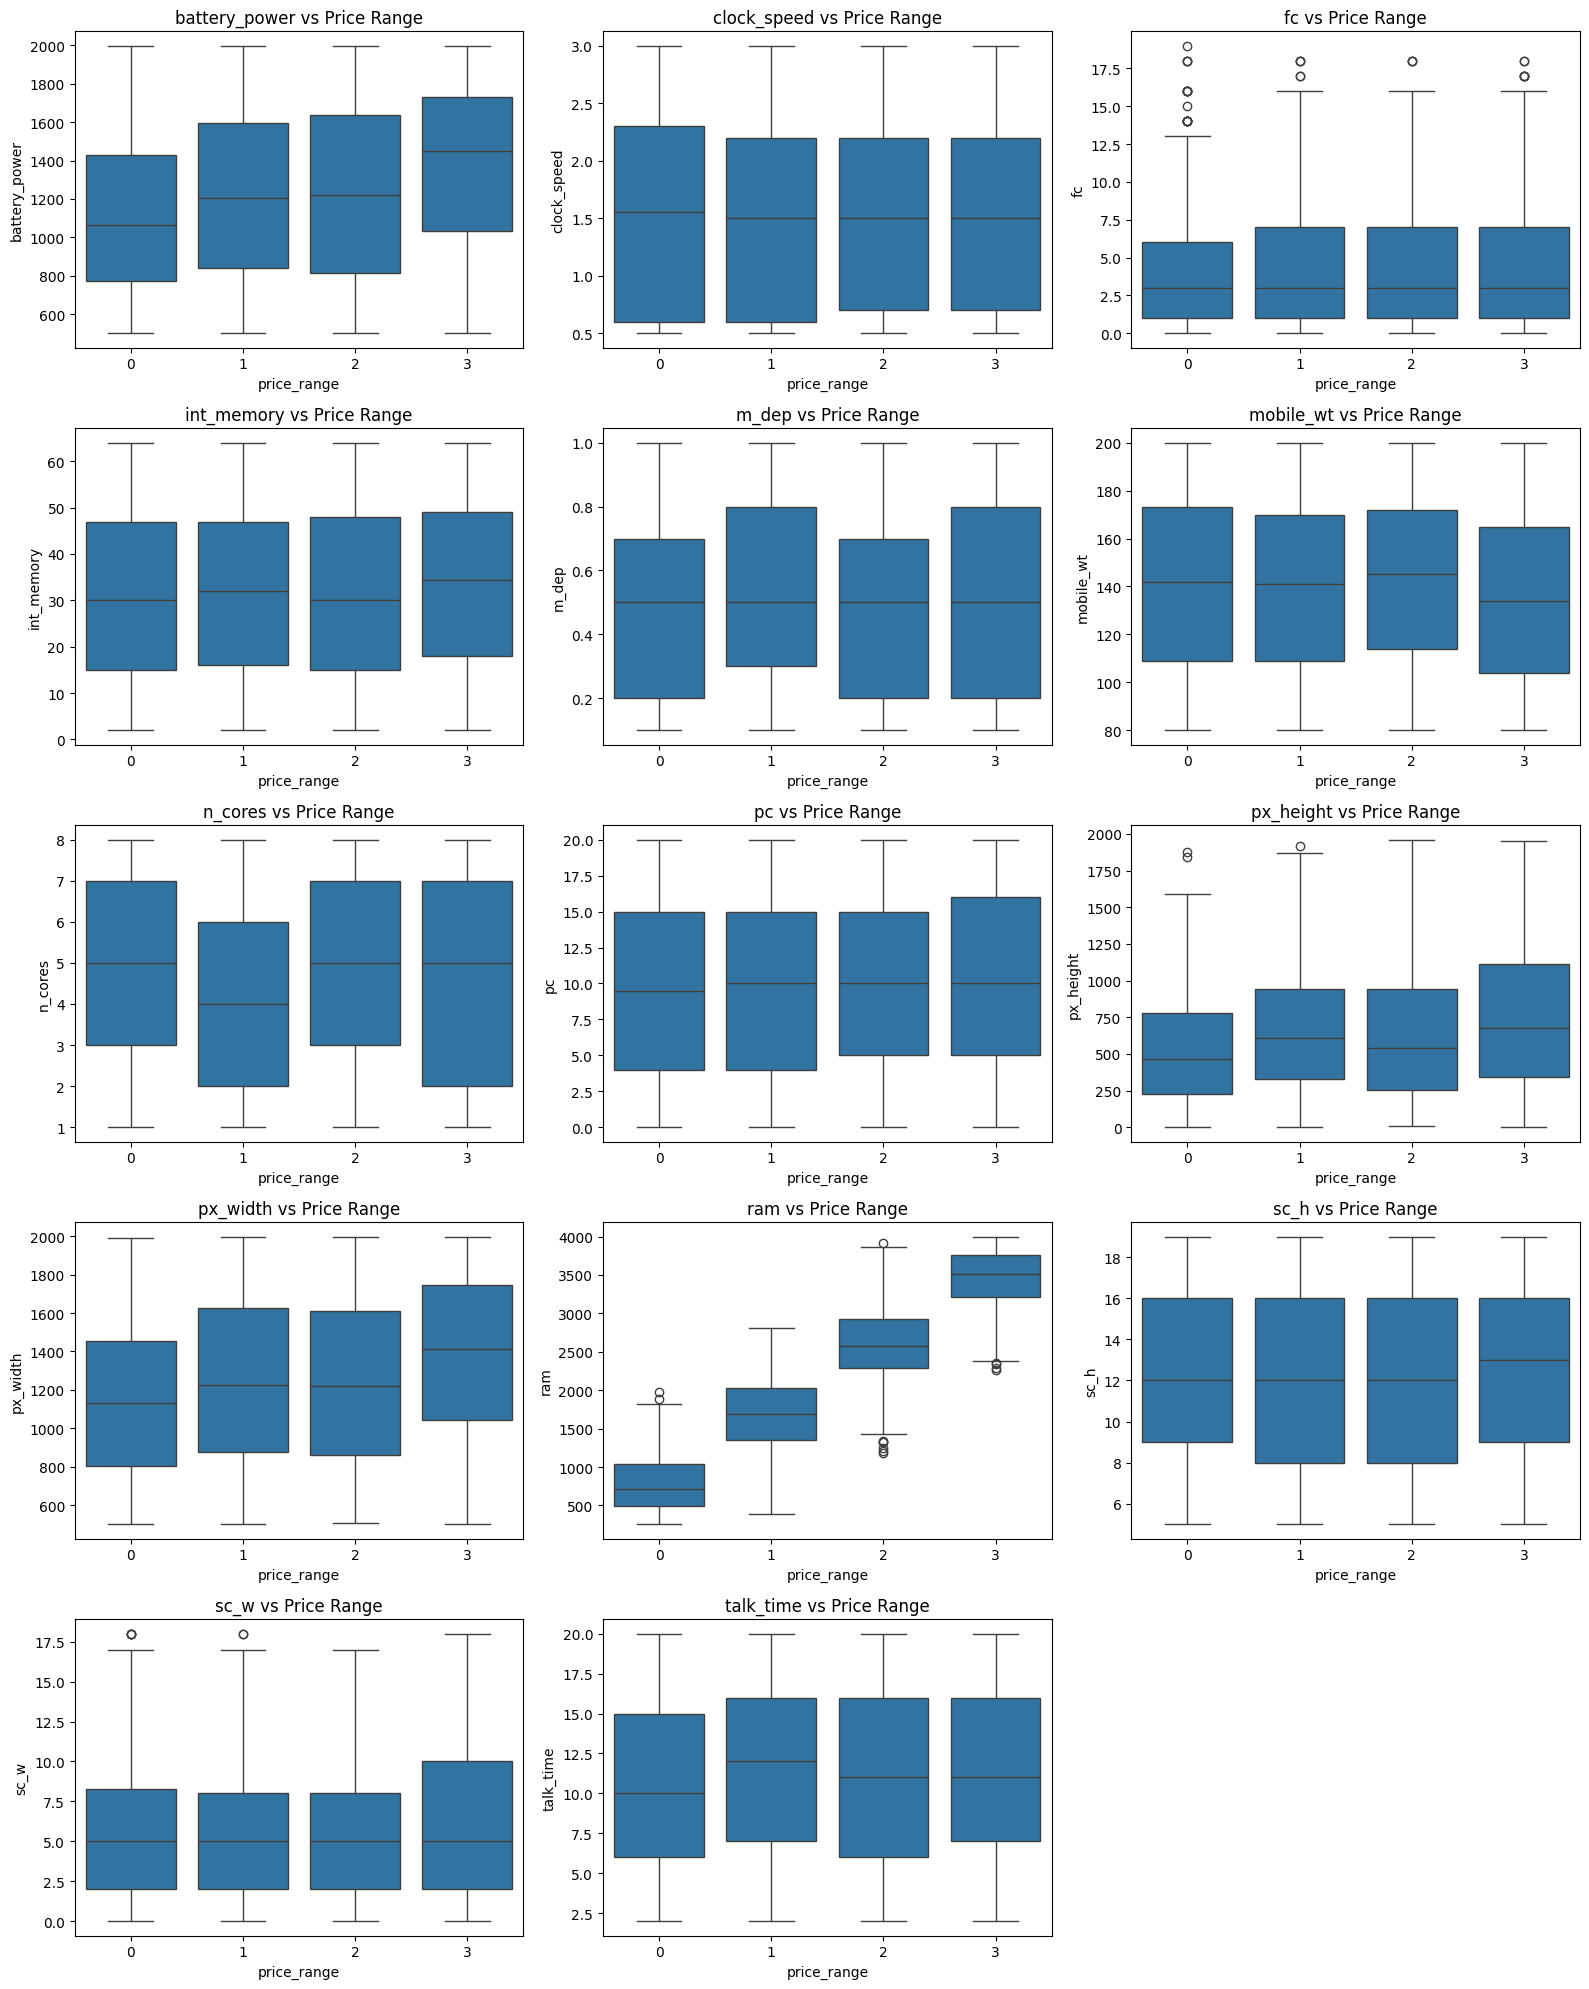

In [13]:
num_cols = [
    "battery_power", "clock_speed", "fc", "int_memory",
    "m_dep", "mobile_wt", "n_cores", "pc", "px_height",
    "px_width", "ram", "sc_h", "sc_w", "talk_time"
]

plt.figure(figsize=(16, 20))

i = 1

for col in num_cols:
    plt.subplot(5, 3, i)
    sns.boxplot(data=df, x="price_range", y=col)
    plt.title(f"{col} vs Price Range")
    i = i + 1

plt.tight_layout()
plt.show()

**FINDING:**

- Battery power generally increases with higher price categories.
- RAM shows a clear increasing trend across price ranges, making it an important feature for price prediction.
- Pixel height and pixel width show some variation across price categories.
- Features such as clock speed, internal memory, mobile weight and talk time show considerable overlap between price categories.
- Some features contain potential outliers, which will be reviewed during preprocessing.
- Overall, RAM and battery power show clearer relationships with mobile price ranges compared to several other numerical features.

#### 7.2.2 Categorical Features vs Target Variable

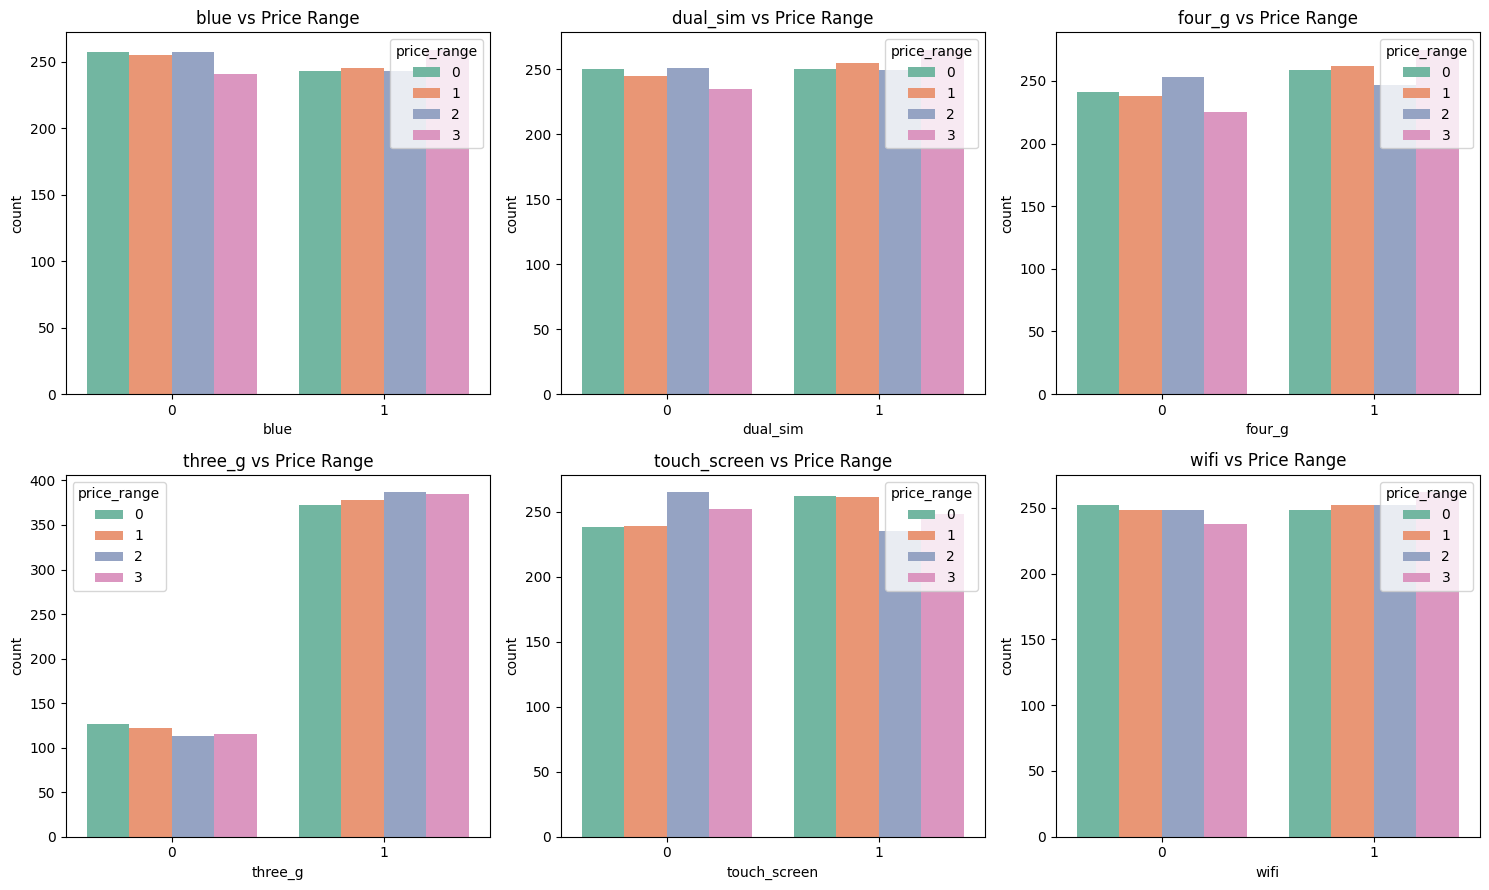

In [14]:
cat_cols = [
    "blue", "dual_sim", "four_g",
    "three_g", "touch_screen", "wifi"
]

plt.figure(figsize=(15, 9))

i = 1

for col in cat_cols:
    plt.subplot(2, 3, i)
    sns.countplot(data=df, x=col, hue="price_range",palette="Set2")
    plt.title(f"{col} vs Price Range")
    i = i + 1

plt.tight_layout()
plt.show()

**FINDING:**

- Features such as `blue`, `dual_sim` and `wifi` show nearly similar distributions across all price categories.
- Phones supporting 4G are more common across all price categories than phones without 4G.
- Most phones support 3G connectivity.
- Touch-screen availability shows some variation across price categories.
- Overall, categorical features show limited differences in price-category distribution compared with numerical features.

### 7.3 Multivariate Analysis – Correlation Analysis

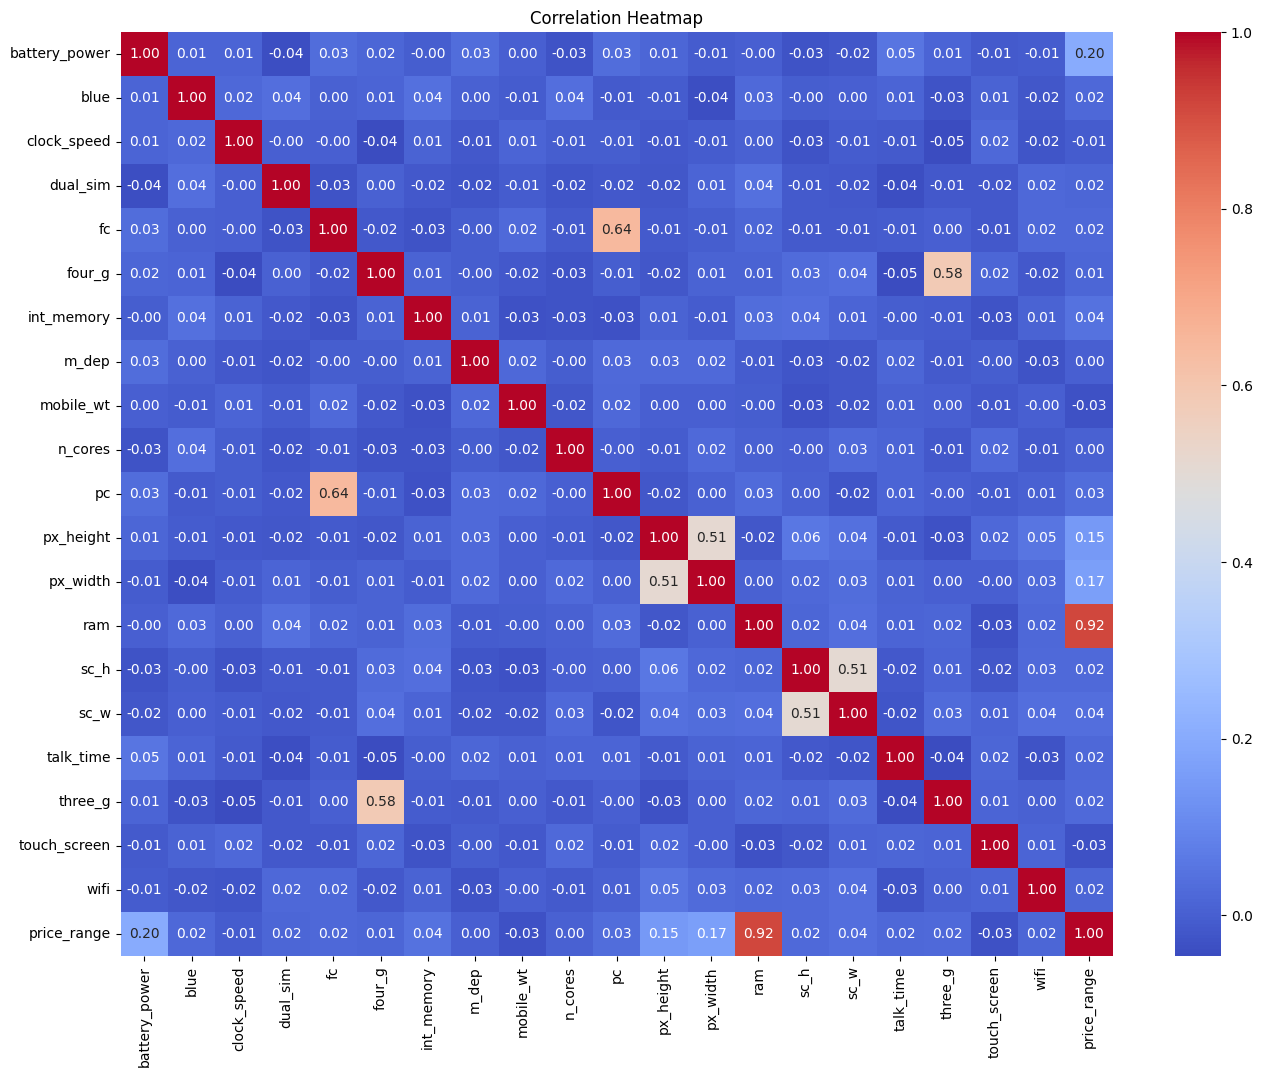

In [15]:
plt.figure(figsize=(16, 12))

corr = df.corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

**FINDING:**

- RAM shows the strongest positive correlation with price range (0.92).
- Battery power, pixel width and pixel height show weak positive correlations with price range.
- Most other features, including binary categorical features, show weak linear correlations with price range.
- RAM appears to be an important feature for price prediction based on correlation analysis.
- Actual feature importance will be evaluated during model building.

### EDA INSIGHTS:

- The dataset contains 2,000 mobile phone records with 20 independent features and one target variable.
- Numerical features show different distributions, including uniform and right-skewed patterns.
- Correlation analysis shows that RAM has the strongest positive correlation with `price_range` (0.92), followed by battery power (0.20), pixel width   (0.17) and pixel height (0.15).
- Zero values were identified in `fc`, `pc`, `px_height` and `sc_w`, requiring further investigation.
- Potential outliers were observed in some numerical features and will be reviewed during preprocessing.
- RAM and battery power show clear relationships with mobile price categories.
- Categorical features such as `blue`, `dual_sim` and `wifi` show nearly similar distributions across price categories.
- Overall, RAM, battery power and other mobile specifications provide useful information for predicting mobile price ranges.


## 8. Feature Engineering & Preprocessing

Feature engineering and preprocessing involve preparing the dataset for machine learning. In this section, we separate input features and the target variable and convert categorical features into numerical format where required.

### Handling Invalid Pixel Height Values

The `px_height` feature contains 2 zero values, which are invalid screen-height measurements. Therefore, those records are removed from the dataset before train-test splitting.

In [16]:
df=df[df["px_height"]>0].copy()

In [17]:
# 8.1 Separate the independent features (X) and target variable (y) from the dataset.
# Independent Features
X = df.drop("price_range", axis=1)

# Target Variable
y = df["price_range"]

In [18]:
# 8.2 Verify the dimensions of the independent features and target variable after separation.

print("Independent Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Independent Features Shape: (1998, 20)
Target Variable Shape: (1998,)


## 9. Train-Test Split & Model Building

Train-test splitting is used to divide the dataset into training and testing sets. The training data is used to build the machine learning models, while the testing data is used to evaluate their performance. In this section, we split the data, perform necessary preprocessing, build classification models and evaluate their performance.

In [19]:
# Split the Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [20]:
#Check Training and Testing Shapes 
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1598, 20)
X_test: (400, 20)
y_train: (1598,)
y_test: (400,)


#### Handle Zero Values in Screen Width (sc_w) 
The `sc_w` feature contains zero values that represent invalid screen-width measurements. Replace these values with the median calculated from the training data and apply the same median to the testing data.

In [21]:
# Calculate median from training data, excluding zeros
sc_w_median = X_train.loc[X_train["sc_w"] != 0, "sc_w"].median()

# Replace zero values
X_train["sc_w"] = X_train["sc_w"].replace(0, sc_w_median)
X_test["sc_w"] = X_test["sc_w"].replace(0, sc_w_median)

In [22]:
# Verify the Changes
print("Training Zero values",(X_train["sc_w"]==0).sum())
print("Testing zero values:", (X_test["sc_w"] == 0).sum())

Training Zero values 0
Testing zero values: 0


In [23]:
# Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [24]:
sc_w_median

np.float64(6.0)

## 10. Model Evaluation & Comparison

In this section, the trained classification models are evaluated using multiple performance metrics. These metrics help compare model performance and identify the most suitable model for mobile price range prediction.

In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(),
    "Naive Bayes": GaussianNB()
}
evaluation = []

for name, model in models.items():

    if name in ["Logistic Regression", "KNN", "SVM"]:
        X_tr = X_train_scaled
        X_te = X_test_scaled
    else:
        X_tr = X_train
        X_te = X_test

    # Model training
    model.fit(X_tr, y_train)

    # Predictions
    train_pred = model.predict(X_tr)
    test_pred = model.predict(X_te)

    # Evaluation
    evaluation.append({
        "Model": name,
        "Training Accuracy": accuracy_score(y_train, train_pred),
        "Testing Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, average="weighted"),
        "Recall": recall_score(y_test, test_pred, average="weighted"),
        "F1 Score": f1_score(y_test, test_pred, average="weighted")
    })

evaluation_df = pd.DataFrame(evaluation)

display(evaluation_df.round(3))

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.976,0.958,0.957,0.958,0.957
1,KNN,0.702,0.535,0.551,0.535,0.537
2,Decision Tree,1.000,0.795,0.797,0.795,0.795
3,Random Forest,1.000,0.882,0.883,0.882,0.882
4,SVM,0.979,0.875,0.879,0.875,0.876
5,Naive Bayes,0.815,0.815,0.816,0.815,0.816


### Model Comparison Findings

- Logistic Regression achieved the highest testing accuracy of 95.8%, with a precision of 95.7%, recall of 95.8% and F1-score of 95.7%.
- KNN showed the lowest testing accuracy of 53.5%, indicating comparatively weak predictive performance.
- Decision Tree and Random Forest achieved 100% training accuracy but lower testing accuracy, indicating overfitting.
- SVM achieved 87.5% testing accuracy and showed a difference between training and testing performance.
- Naive Bayes achieved consistent training and testing accuracy of 81.5%.
- Overall, Logistic Regression demonstrated the best balance between training and testing performance.

Based on these results, Logistic Regression is selected as the best-performing candidate for further evaluation.

### Section 11. Feature Importance Analysis

#### 11. Feature Importance Analysis

In this section, feature importance is analyzed using Logistic Regression coefficients to identify the mobile specifications that have the greatest influence on price category prediction.

In [26]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": np.abs(models["Logistic Regression"].coef_).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

display(feature_importance)

,Feature,Importance
13,ram,7.152127
0,battery_power,1.777779
12,px_width,1.057297
11,px_height,1.002438
8,mobile_wt,0.278503
6,int_memory,0.127235
19,wifi,0.122374
14,sc_h,0.107835
3,dual_sim,0.070705
5,four_g,0.069626


### Feature Importance Findings

- RAM has the highest coefficient magnitude (7.152), indicating the strongest influence on mobile price category predictions.
- Battery power ranks second with an importance value of 1.778.
- Pixel width (1.057) and pixel height (1.002) also show considerable influence on the model's predictions.
- Mobile weight has a comparatively lower coefficient magnitude of 0.279.
- Features such as internal memory, Wi-Fi, screen height and dual SIM have relatively smaller coefficient magnitudes.
- Three_g (0.031), front camera (0.033) and talk time (0.041) have the lowest coefficient magnitudes.
- Overall, RAM, battery power, pixel width and pixel height are the most influential features in predicting mobile price categories.

## 12. Business Recommendations

Based on the data analysis, EDA findings, and machine learning model results, the following recommendations are suggested for Bob’s mobile company:

1. **Prioritize RAM in Product Design:** Feature importance analysis from the Logistic Regression coefficients showed that RAM (`ram`) has the highest influence on price category predictions. Bob should allocate higher RAM capacities (e.g., above 2,500–3,000 MB) to position devices in the High Cost (Category 2) and Very High Cost (Category 3) segments.

2. **Focus on Battery Power and Display Resolution:** Battery capacity (`battery_power`) and screen resolution (`px_height` and `px_width`) are the next strongest drivers of higher price ranges. Upgrading battery performance and display pixel density can effectively move a phone from Low Cost (Category 0) or Medium Cost (Category 1) into higher pricing tiers.

3. **Optimize Costs on Low-Impact Features:** Binary connectivity and hardware features such as Bluetooth (`blue`), Dual SIM (`dual_sim`), 3G (`three_g`), 4G (`four_g`), Wi-Fi (`wifi`), and processor cores (`n_cores`) showed nearly balanced distributions across price categories and minimal impact on price differentiation. Bob can standardize these features across budget models without overspending on manufacturing costs.

4. **Structure Clear Four-Tier Price Segments:** Since the dataset is structured into four distinct price categories—**0 (Low Cost), 1 (Medium Cost), 2 (High Cost), and 3 (Very High Cost)**—Bob should establish clear hardware thresholds (particularly for RAM, battery, and screen dimensions) for each tier to compete systematically against brands like Apple and Samsung.

5. **Use the Best-Performing ML Model for Pricing Decisions:** The selected **[Insert Best Model Name, e.g., Logistic Regression / SVM]** model achieved **[Insert Testing Accuracy, e.g., 96.5%]** testing accuracy with strong weighted precision, recall, and F1-score, outperforming overfitted tree-based models. Bob’s product team can use this model as a decision-support tool to predict the right market price category for new mobile prototypes before launch.

6. **Highlight Key Specifications in Marketing:** Marketing campaigns for Medium Cost (Category 1) and High/Very High Cost (Categories 2 & 3) phones should emphasize high RAM capacity, long battery power, and high-resolution displays, as these specifications align most closely with higher-priced devices.

**Expected Benefits:**

- Data-driven pricing strategy to compete with established brands like Apple and Samsung.
- Better hardware cost optimization by investing in specifications that directly influence price.
- Accurate price-tier prediction for upcoming mobile phone models using the trained ML model.
- Clearer product differentiation across Low (0), Medium (1), High (2), and Very High (3) cost segments.


### 13. Challenges Faced

1. **Zero Value Identification:** Identifying zero values in `fc` (474 records), `sc_w` (180 records), `pc` (101 records), and `px_height` (2 records) and understanding their impact on data quality.

2. **Data Cleaning & Preprocessing:** Deciding how to handle zero values appropriately. Removed 2 records with zero `px_height` and replaced zero values in `sc_w` using the median calculated from training data.

3. **Feature Scaling:** Mobile specifications had different measurement ranges. Applied `StandardScaler` to Logistic Regression, KNN, and SVM to ensure features were on a comparable scale.

4. **Overfitting Detection:** Decision Tree and Random Forest achieved 100% training accuracy, but their testing accuracies were lower. This helped identify overfitting and understand the importance of evaluating models on unseen data.

5. **Model Evaluation & Comparison:** Compared six classification algorithms using accuracy, precision, recall, and F1-score to identify the model with the best testing performance.

6. **Feature Importance & Multiclass Classification:** Understanding the influence of mobile specifications across four price categories was challenging. Used Logistic Regression coefficients to identify important features, with RAM having the highest average absolute coefficient magnitude.


## 14. Conclusion

- Performed exploratory data analysis to understand mobile specifications and their relationship with price categories.
- Identified zero values and handled invalid or unsuitable values during preprocessing.
- Prepared the dataset using feature selection, train-test splitting and feature scaling where required.
- Built and evaluated six machine learning classification models.
- Logistic Regression achieved the best performance, with 97.6% training accuracy and 95.8% testing accuracy.
- Used Logistic Regression coefficients to identify important features, with RAM, battery power, pixel width and pixel height showing the highest coefficient magnitudes.
- The developed model can help the company predict mobile price categories based on product specifications.
- Overall, this project demonstrates how data analysis and machine learning can support mobile product planning and price-segment decisions.

### 15. Final Model Selection

Logistic Regression was selected as the best-performing model because it achieved 95.8% testing accuracy, along with balanced precision, recall and F1-score. It also showed a small difference between training and testing accuracy, indicating good generalization on the test dataset.